# AIML Lab Exercise 5: (i) Multiple Linear Regression and (ii) Logistic Regression
**Datasets:** Synthetic House Price Dataset (house_prices.csv) and Synthetic Student Admission Dataset (student_admission.csv)

This notebook implements both models **from scratch** with NumPy (least squares / normal equation, gradient descent, sigmoid, log-loss) and verifies the results against scikit-learn.
- **Part (i)** predicts a continuous value (house price) from several features — a **regression** problem.
- **Part (ii)** predicts a class (admitted or not) from two exam scores — a **classification** problem — and evaluates it with a confusion matrix, precision, recall and the ROC curve.

## 1. Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score)

print("Libraries imported successfully!")

Libraries imported successfully!


---
# Part (i): Multiple Linear Regression
The model assumes the target is a linear combination of the features:

$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$$

and finds the θ values that minimise the **Mean Squared Error** cost function

$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

## 2. Load the dataset and display basic information

In [2]:
house = pd.read_csv('house_prices.csv')
print("Dataset loaded successfully!")
print("Shape:", house.shape)
house.info()
display(house.head())

Dataset loaded successfully!
Shape: (250, 5)
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area_sqft          250 non-null    int64  
 1   Bedrooms           250 non-null    int64  
 2   HouseAge           250 non-null    int64  
 3   DistanceToCity_km  250 non-null    float64
 4   Price              250 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 9.9 KB


,Area_sqft,Bedrooms,HouseAge,DistanceToCity_km,Price
0,858,2,33,2.6,166634.78
1,2844,5,38,9.1,408226.58
2,2498,4,16,10.7,389222.87
3,1872,4,4,6.0,343802.38
4,1855,2,10,10.1,302855.35


## 3. Check missing values and summary statistics

In [3]:
print("Missing values per column:\n", house.isnull().sum())
display(house.describe())

Missing values per column:
 Area_sqft            0
Bedrooms             0
HouseAge             0
DistanceToCity_km    0
Price                0
dtype: int64


,Area_sqft,Bedrooms,HouseAge,DistanceToCity_km,Price
count,250.000000,250.000000,250.000000,250.000000,250.000000
mean,2068.716000,2.996000,19.076000,15.374400,298236.517120
std,791.387934,1.381164,11.798093,8.516447,115658.452809
min,621.000000,1.000000,0.000000,1.000000,48011.740000
25%,1406.250000,2.000000,9.000000,8.225000,200096.152500
50%,2047.000000,3.000000,20.000000,15.100000,299370.060000
75%,2758.000000,4.000000,29.000000,22.875000,397573.572500
max,3488.000000,6.000000,39.000000,30.000000,517075.370000


## 4. Exploratory analysis: correlation and feature-vs-target plots

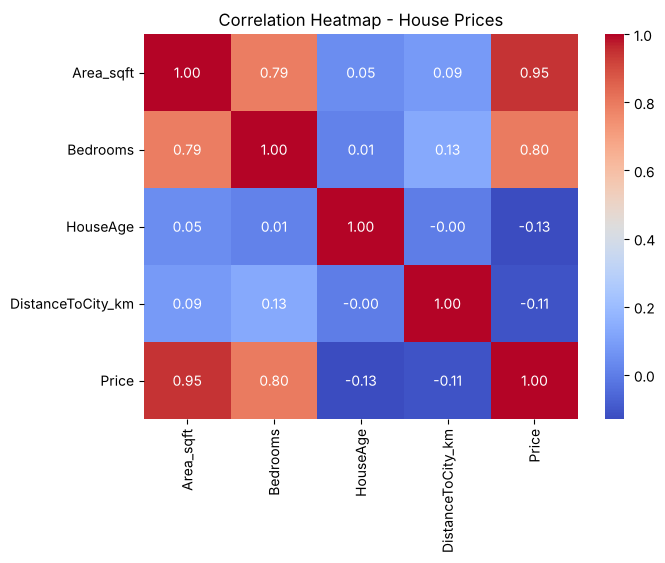

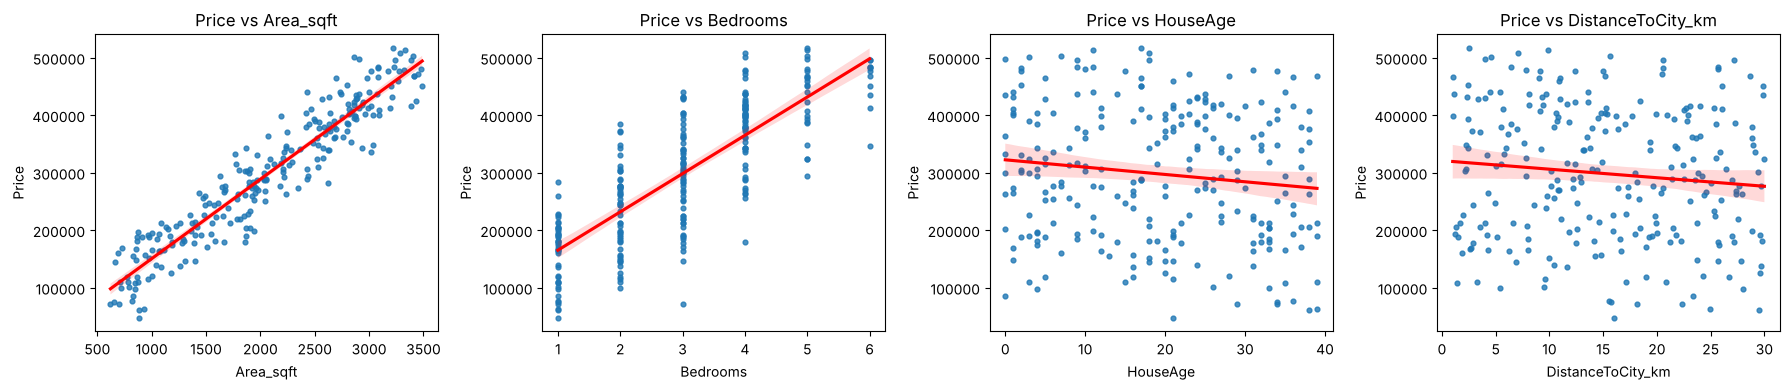

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(house.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - House Prices')
plt.show()

features = ['Area_sqft', 'Bedrooms', 'HouseAge', 'DistanceToCity_km']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.regplot(x=house[col], y=house['Price'], ax=ax, scatter_kws={'s': 12}, line_kws={'color': 'red'})
    ax.set_title(f'Price vs {col}')
plt.tight_layout()
plt.show()

**Interpretation:** `Area_sqft` and `Bedrooms` are positively correlated with price, while `HouseAge` and `DistanceToCity_km` are negatively correlated — older houses and houses far from the city are cheaper.

## 5. Split the dataset into training and testing sets

In [5]:
X = house[features].values
y = house['Price'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape, " Testing set:", X_test.shape)

Training set: (200, 4)  Testing set: (50, 4)


## 6. Least squares solution using the Normal Equation (from scratch)
The closed-form least-squares solution is

$$\theta = (X^T X)^{-1} X^T y$$

A column of ones is added to X for the intercept θ₀.

In [6]:
def add_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

Xb_train = add_bias(X_train)
theta_ne = np.linalg.inv(Xb_train.T @ Xb_train) @ Xb_train.T @ y_train

print("Intercept (theta_0):", round(theta_ne[0], 2))
for name, coef in zip(features, theta_ne[1:]):
    print(f"{name:20s}: {coef:10.2f}")

Intercept (theta_0): 78194.09
Area_sqft           :     124.33
Bedrooms            :   12498.95
HouseAge            :   -1674.76
DistanceToCity_km   :   -2816.18


## 7. Gradient descent implementation (from scratch)
Gradient descent repeatedly updates the parameters in the direction that decreases the cost:

$$\theta_j := \theta_j - \alpha \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)x_j^{(i)}$$

Features are **standardized** first so that gradient descent converges quickly.

In [7]:
scaler_lr = StandardScaler()
X_train_s = scaler_lr.fit_transform(X_train)
X_test_s = scaler_lr.transform(X_test)

def gradient_descent(X, y, alpha=0.1, iterations=500):
    Xb = add_bias(X)
    m, n = Xb.shape
    theta = np.zeros(n)
    cost_history = []
    for _ in range(iterations):
        error = Xb @ theta - y
        cost_history.append((error ** 2).sum() / (2 * m))
        theta -= alpha * (Xb.T @ error) / m
    return theta, cost_history

theta_gd, cost_history = gradient_descent(X_train_s, y_train)

# Convert the coefficients back to the original feature scale for comparison
coef_gd = theta_gd[1:] / scaler_lr.scale_
intercept_gd = theta_gd[0] - (coef_gd * scaler_lr.mean_).sum()
print("Intercept (theta_0):", round(intercept_gd, 2))
for name, coef in zip(features, coef_gd):
    print(f"{name:20s}: {coef:10.2f}")
print("\nFinal cost J(theta):", round(cost_history[-1], 2))

Intercept (theta_0): 78194.43
Area_sqft           :     124.33
Bedrooms            :   12499.49
HouseAge            :   -1674.76
DistanceToCity_km   :   -2816.18

Final cost J(theta): 195113665.09


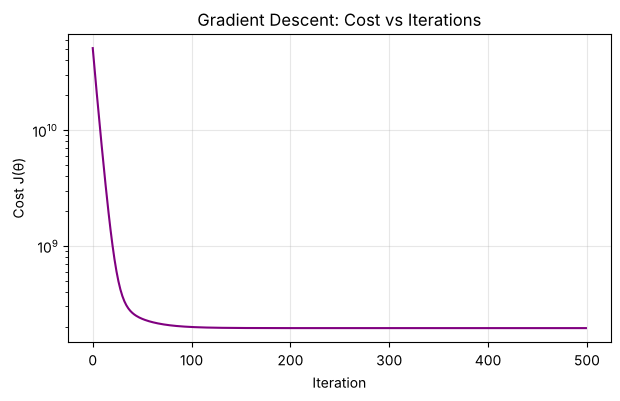

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(cost_history, color='purple')
plt.xlabel('Iteration')
plt.ylabel('Cost J(θ)')
plt.title('Gradient Descent: Cost vs Iterations')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.show()

## 8. Multiple linear regression using scikit-learn and comparison

In [9]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

coef_table = pd.DataFrame({
    'Normal Equation': theta_ne,
    'Gradient Descent': np.r_[intercept_gd, coef_gd],
    'scikit-learn': np.r_[lin_reg.intercept_, lin_reg.coef_],
}, index=['Intercept'] + features).round(2)
display(coef_table)

,Normal Equation,Gradient Descent,scikit-learn
Intercept,78194.09,78194.43,78194.09
Area_sqft,124.33,124.33,124.33
Bedrooms,12498.95,12499.49,12498.95
HouseAge,-1674.76,-1674.76,-1674.76
DistanceToCity_km,-2816.18,-2816.18,-2816.18


**Interpretation:** All three methods give (almost) identical coefficients. For example, each extra square foot adds about 120 to the price, and every extra km from the city reduces it by about 2,800.

## 9. Evaluate the regression model on the test set

In [10]:
y_pred = lin_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)     : {mae:,.2f}")
print(f"Mean Squared Error (MSE)      : {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² score                      : {r2:.4f}")

Mean Absolute Error (MAE)     : 16,442.67
Mean Squared Error (MSE)      : 455,595,240.36
Root Mean Squared Error (RMSE): 21,344.68
R² score                      : 0.9675


## 10. Visualize actual vs predicted values and residuals

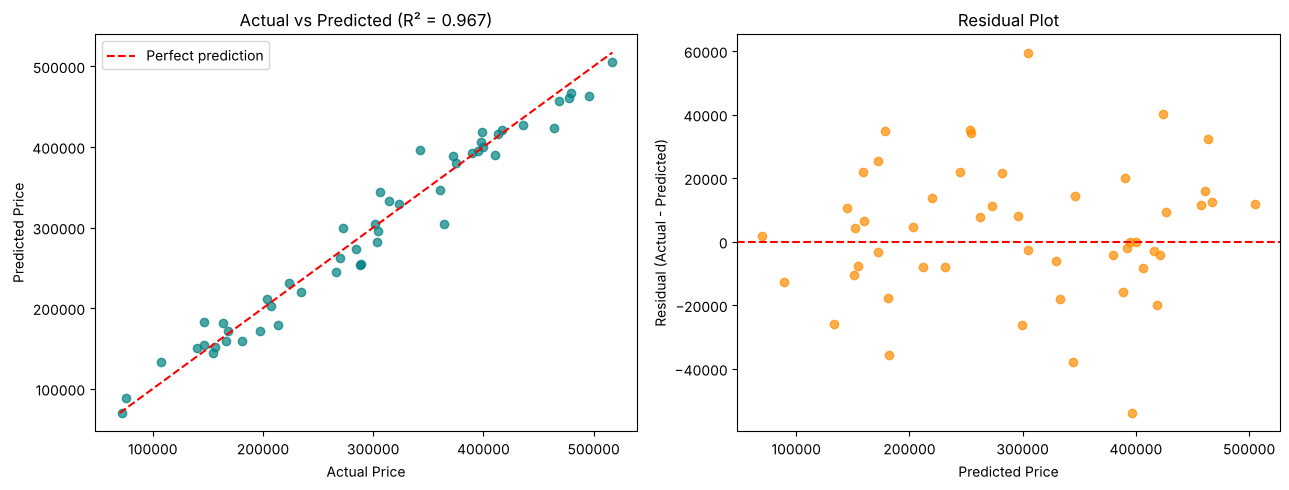

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, color='teal', alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title(f'Actual vs Predicted (R² = {r2:.3f})')
axes[0].legend()

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, color='darkorange', alpha=0.7)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')
plt.tight_layout()
plt.show()

**Interpretation:** The points lie close to the diagonal and the residuals are randomly scattered around zero with no visible pattern, which shows that a linear model fits this data well.

## 11. Predict the price of a new house

In [12]:
new_house = pd.DataFrame([[2000, 3, 10, 5.0]], columns=features)
print(new_house.to_string(index=False))
print("\nPredicted price:", round(lin_reg.predict(new_house.values)[0], 2))

 Area_sqft  Bedrooms  HouseAge  DistanceToCity_km
      2000         3        10                5.0

Predicted price: 333519.99


---
# Part (ii): Logistic Regression
Logistic regression is used for **binary classification**. The hypothesis passes the linear combination through the **sigmoid function**, giving a probability between 0 and 1:

$$h_\theta(x) = \sigma(\theta^T x) = \frac{1}{1 + e^{-\theta^T x}}$$

It is trained by minimising the **log-loss (binary cross-entropy)** cost:

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log h_\theta(x^{(i)}) + (1 - y^{(i)})\log(1 - h_\theta(x^{(i)}))\right]$$

## 12. Load the dataset and visualize the two classes

Dataset loaded successfully! Shape: (200, 3)
Missing values: 0


,Exam1_Score,Exam2_Score,Admitted
0,42.41,66.53,0
1,77.47,52.03,1
2,89.22,69.49,1
3,32.82,77.37,0
4,61.47,34.63,0



Class distribution:
 Admitted
0    111
1     89
Name: count, dtype: int64


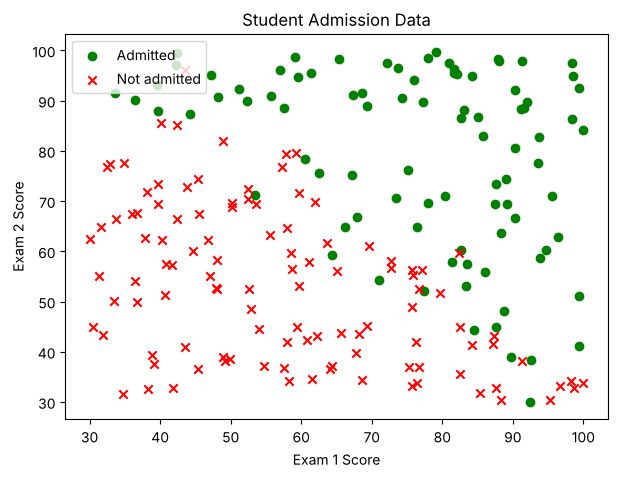

In [13]:
admit = pd.read_csv('student_admission.csv')
print("Dataset loaded successfully! Shape:", admit.shape)
print("Missing values:", admit.isnull().sum().sum())
display(admit.head())
print("\nClass distribution:\n", admit['Admitted'].value_counts())

plt.figure(figsize=(7, 5))
for label, marker, color in [(1, 'o', 'green'), (0, 'x', 'red')]:
    subset = admit[admit['Admitted'] == label]
    plt.scatter(subset['Exam1_Score'], subset['Exam2_Score'], marker=marker, color=color,
                label='Admitted' if label else 'Not admitted')
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Student Admission Data')
plt.legend()
plt.show()

## 13. Sigmoid function and its derivative
The derivative of the sigmoid has a simple form that is used in gradient descent:

$$\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$$

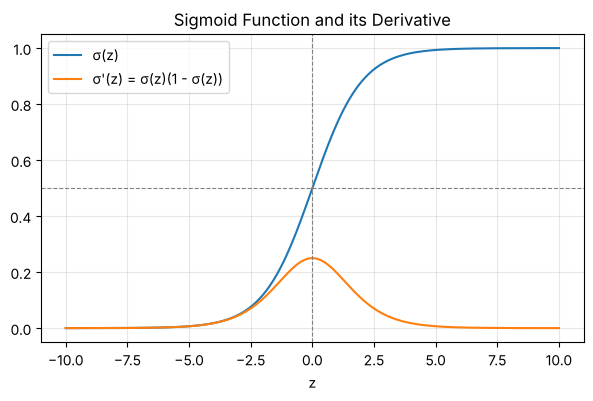

In [14]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-10, 10, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z), label='σ(z)')
plt.plot(z, sigmoid_derivative(z), label="σ'(z) = σ(z)(1 - σ(z))")
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('Sigmoid Function and its Derivative')
plt.xlabel('z')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 14. Split and standardize the data

In [15]:
Xc = admit[['Exam1_Score', 'Exam2_Score']].values
yc = admit['Admitted'].values

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)
scaler_log = StandardScaler()
Xc_train_s = scaler_log.fit_transform(Xc_train)
Xc_test_s = scaler_log.transform(Xc_test)
print("Training set:", Xc_train_s.shape, " Testing set:", Xc_test_s.shape)

Training set: (150, 2)  Testing set: (50, 2)


## 15. Train logistic regression with gradient descent (from scratch)
The gradient of the log-loss has the same form as in linear regression:

$$\theta_j := \theta_j - \alpha\frac{1}{m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)}) - y^{(i)}\right)x_j^{(i)}$$

Learned parameters (on standardized features): [-0.1521  3.3412  4.2373]
Final training log-loss: 0.2081


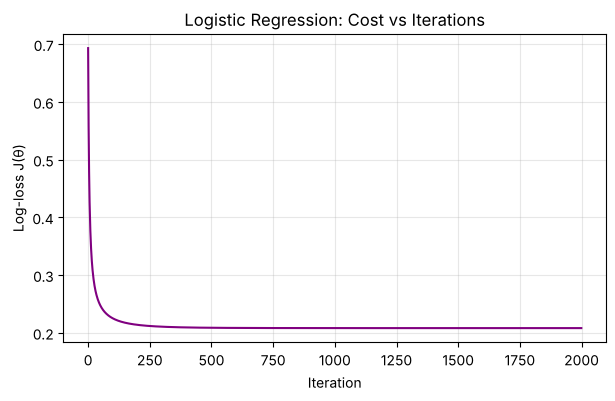

In [16]:
def log_loss(h, y):
    eps = 1e-12
    return -np.mean(y * np.log(h + eps) + (1 - y) * np.log(1 - h + eps))

def logistic_gradient_descent(X, y, alpha=0.5, iterations=2000):
    Xb = add_bias(X)
    theta = np.zeros(Xb.shape[1])
    history = []
    for _ in range(iterations):
        h = sigmoid(Xb @ theta)
        history.append(log_loss(h, y))
        theta -= alpha * (Xb.T @ (h - y)) / len(y)
    return theta, history

theta_log, log_history = logistic_gradient_descent(Xc_train_s, yc_train)
print("Learned parameters (on standardized features):", theta_log.round(4))
print("Final training log-loss:", round(log_history[-1], 4))

plt.figure(figsize=(7, 4))
plt.plot(log_history, color='purple')
plt.xlabel('Iteration')
plt.ylabel('Log-loss J(θ)')
plt.title('Logistic Regression: Cost vs Iterations')
plt.grid(alpha=0.3)
plt.show()

## 16. Plot the decision boundary
The decision boundary is the line where h(x) = 0.5, i.e. θ₀ + θ₁x₁ + θ₂x₂ = 0. Points on one side are predicted *admitted*, points on the other side *not admitted*.

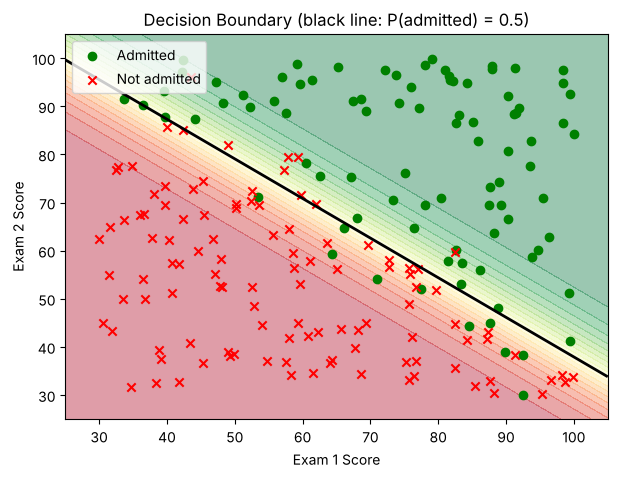

In [17]:
def predict_proba_scratch(X_scaled):
    return sigmoid(add_bias(X_scaled) @ theta_log)

xx, yy = np.meshgrid(np.linspace(25, 105, 300), np.linspace(25, 105, 300))
grid_probs = predict_proba_scratch(scaler_log.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, grid_probs, levels=20, cmap='RdYlGn', alpha=0.4)
plt.contour(xx, yy, grid_probs, levels=[0.5], colors='black', linewidths=2)
for label, marker, color in [(1, 'o', 'green'), (0, 'x', 'red')]:
    mask = yc == label
    plt.scatter(Xc[mask, 0], Xc[mask, 1], marker=marker, color=color,
                label='Admitted' if label else 'Not admitted')
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Decision Boundary (black line: P(admitted) = 0.5)')
plt.legend()
plt.show()

## 17. Logistic regression using scikit-learn and comparison

In [18]:
log_reg = LogisticRegression()
log_reg.fit(Xc_train_s, yc_train)

pred_scratch = (predict_proba_scratch(Xc_test_s) >= 0.5).astype(int)
pred_sklearn = log_reg.predict(Xc_test_s)

print("Test accuracy (from scratch):", accuracy_score(yc_test, pred_scratch))
print("Test accuracy (scikit-learn):", accuracy_score(yc_test, pred_sklearn))
print(f"Both models agree on {(pred_scratch == pred_sklearn).mean() * 100:.0f}% of the test predictions")

Test accuracy (from scratch): 0.9
Test accuracy (scikit-learn): 0.88
Both models agree on 98% of the test predictions


## 18. Evaluate the classifier: confusion matrix, precision, recall and F1-score
- **Precision** = TP / (TP + FP) — of the students predicted *admitted*, how many really were
- **Recall** = TP / (TP + FN) — of the students really admitted, how many were found
- **F1-score** = harmonic mean of precision and recall

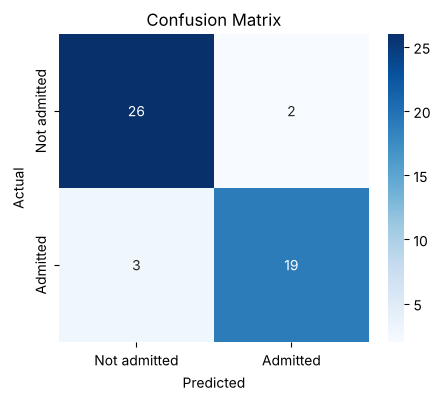

Accuracy : 0.9000
Precision: 0.9048
Recall   : 0.8636
F1-score : 0.8837

Classification report:
               precision    recall  f1-score   support

Not admitted       0.90      0.93      0.91        28
    Admitted       0.90      0.86      0.88        22

    accuracy                           0.90        50
   macro avg       0.90      0.90      0.90        50
weighted avg       0.90      0.90      0.90        50



In [19]:
cm = confusion_matrix(yc_test, pred_scratch)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not admitted', 'Admitted'], yticklabels=['Not admitted', 'Admitted'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(f"Accuracy : {accuracy_score(yc_test, pred_scratch):.4f}")
print(f"Precision: {precision_score(yc_test, pred_scratch):.4f}")
print(f"Recall   : {recall_score(yc_test, pred_scratch):.4f}")
print(f"F1-score : {f1_score(yc_test, pred_scratch):.4f}")
print("\nClassification report:\n", classification_report(yc_test, pred_scratch, target_names=['Not admitted', 'Admitted']))

## 19. ROC curve and AUC
The ROC curve plots the **True Positive Rate** against the **False Positive Rate** for every probability threshold. The **Area Under the Curve (AUC)** summarises it: 1.0 is a perfect classifier and 0.5 is random guessing.

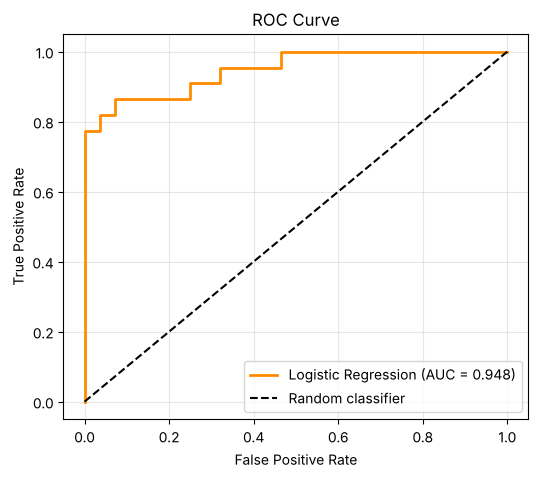

In [20]:
probs = predict_proba_scratch(Xc_test_s)
fpr, tpr, _ = roc_curve(yc_test, probs)
auc = roc_auc_score(yc_test, probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', linewidth=2, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 20. Predict admission for new students

In [21]:
new_students = np.array([[45, 85], [70, 60], [90, 88]])
p = predict_proba_scratch(scaler_log.transform(new_students))
display(pd.DataFrame({'Exam1_Score': new_students[:, 0], 'Exam2_Score': new_students[:, 1],
                      'P(admitted)': p.round(4), 'Prediction': np.where(p >= 0.5, 'Admitted', 'Not admitted')}))

,Exam1_Score,Exam2_Score,P(admitted),Prediction
0,45,85,0.5905,Admitted
1,70,60,0.3703,Not admitted
2,90,88,0.9998,Admitted


## 21. Documentation summary
**Part (i) – Multiple Linear Regression**
1. Loaded and explored the house price dataset (missing values, statistics, correlation, scatter plots)
2. Split the data into training and testing sets
3. Computed the least-squares solution using the Normal Equation
4. Implemented gradient descent on standardized features and plotted the cost curve
5. Compared the coefficients with scikit-learn's `LinearRegression`
6. Evaluated the model using MAE, MSE, RMSE and R², and plotted actual vs predicted values and residuals
7. Predicted the price of a new house

**Part (ii) – Logistic Regression**
1. Loaded and visualized the student admission dataset
2. Implemented and plotted the sigmoid function and its derivative
3. Trained logistic regression from scratch using gradient descent on the log-loss
4. Plotted the decision boundary
5. Compared the results with scikit-learn's `LogisticRegression`
6. Evaluated the classifier with a confusion matrix, precision, recall, F1-score, ROC curve and AUC
7. Predicted the admission probability for new students

**Result:** Multiple linear regression and logistic regression models were implemented successfully. The from-scratch implementations match scikit-learn.